# Group 6 - Predicting Credit Default Risk

This notebook completes the Python code project for the group assignment. It follows a full data analytics workflow: data loading, cleaning, exploratory data analysis, visualization, feature engineering, model building, model evaluation, and business interpretation.

**Prediction target:** `target_default = 1` if `outcome_status == "Charged Off"`; otherwise `target_default = 0`.

In [1]:
# Import libraries
import os
import re
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

## 1. Load the datasets

The assignment provides two CSV files. The main application dataset contains the final loan outcome and is used to build the classification model. The inquiry dataset does not contain the target outcome, so it is used for supplementary EDA and data understanding.

In [4]:
# The notebook checks common locations so it can run both in ChatGPT and on a local computer.
possible_dirs = [
    'datasets',
    './datasets',
    '/mnt/data/credit/datasets'
]

DATA_DIR = None
for folder in possible_dirs:
    if os.path.exists(os.path.join(folder, 'creditrisk_applications_final.csv')):
        DATA_DIR = folder
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the datasets folder. Place the two CSV files in a folder named 'datasets' next to this notebook."
    )

apps = pd.read_csv(os.path.join(DATA_DIR, 'creditrisk_applications_final.csv'))
inq = pd.read_csv(os.path.join(DATA_DIR, 'creditrisk_inquiries_final.csv'))

print('Applications shape:', apps.shape)
print('Inquiries shape:', inq.shape)
display(apps.head())
display(inq.head())

Applications shape: (85000, 22)
Inquiries shape: (45000, 8)


,application_id,requested_amount_usd,repayment_term_text,interest_rate_text,monthly_installment_usd,last_payment_amount_usd,risk_grade_band,risk_grade_detail,employment_tenure_text,housing_status,annual_income_usd,income_verification_status,origination_month,outcome_status,loan_purpose,region_code,debt_to_income_ratio,credit_score_low,credit_score_high,open_credit_lines,public_records_count,revolving_utilization_text
0,41080563,18000.0,60 months,13.33,412.61,15325.62,C,C3,3 years,OWN,105000.0,Verified,Feb-2015,Fully Paid,debt_consolidation,AZ,6.78,670.0,674.0,7.0,0.0,89.5
1,76295652,1000.0,36 months,11.99,33.21,842.45,C,C1,1 year,RENT,28500.0,Not Verified,Apr-2016,Fully Paid,home_improvement,FL,11.54,690.0,694.0,3.0,1.0,13.3
2,60586596,21275.0,36 months,10.99,696.42,7380.80,B,B4,5 years,MORTGAGE,130000.0,Verified,Sep-2015,Fully Paid,debt_consolidation,PA,23.08,680.0,684.0,13.0,0.0,75.7
3,59310389,35000.0,60 months,16.99,869.66,32305.48,D,D3,10+ years,MORTGAGE,107000.0,Source Verified,Sep-2015,Fully Paid,credit_card,SC,16.3,710.0,714.0,10.0,0.0,76.5
4,44516103,17000.0,60 months,17.57,427.73,427.73,D,D4,8 years,RENT,55000.0,Source Verified,Apr-2015,Charged Off,credit_card,CA,31.27,680.0,684.0,8.0,0.0,62.5


,requested_amount_usd,application_date,request_title,screening_score,debt_to_income_text,region_code,employment_tenure_text,policy_code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10%,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10%,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10%,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64%,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43%,MD,< 1 year,0.0


## 2. Initial data inspection

This section checks column types, missing values, duplicates, and the distribution of the loan outcome variable before cleaning.

In [6]:
print('Applications data types')
display(apps.dtypes)

print('Applications missing values')
display(apps.isna().sum().sort_values(ascending=False))

print('Application duplicate rows:', apps.duplicated().sum())
print('Inquiry duplicate rows:', inq.duplicated().sum())

print('Outcome status counts')
display(apps['outcome_status'].value_counts())

Applications data types


application_id                  int64
requested_amount_usd          float64
repayment_term_text               str
interest_rate_text            float64
monthly_installment_usd       float64
last_payment_amount_usd       float64
risk_grade_band                   str
risk_grade_detail                 str
employment_tenure_text            str
housing_status                    str
annual_income_usd             float64
income_verification_status        str
origination_month                 str
outcome_status                    str
loan_purpose                      str
region_code                       str
debt_to_income_ratio              str
credit_score_low              float64
credit_score_high             float64
open_credit_lines             float64
public_records_count          float64
revolving_utilization_text    float64
dtype: object

Applications missing values


employment_tenure_text        8676
revolving_utilization_text     892
debt_to_income_ratio           709
annual_income_usd              680
application_id                   0
requested_amount_usd             0
last_payment_amount_usd          0
monthly_installment_usd          0
interest_rate_text               0
repayment_term_text              0
housing_status                   0
income_verification_status       0
risk_grade_detail                0
risk_grade_band                  0
outcome_status                   0
origination_month                0
region_code                      0
loan_purpose                     0
credit_score_low                 0
credit_score_high                0
open_credit_lines                0
public_records_count             0
dtype: int64

Application duplicate rows: 0
Inquiry duplicate rows: 15
Outcome status counts


outcome_status
Fully Paid     42500
Charged Off    42500
Name: count, dtype: int64

## 3. Create the target variable

The assignment defines default as a charged-off loan. The binary target is therefore created from `outcome_status`.

In [7]:
apps['target_default'] = np.where(apps['outcome_status'] == 'Charged Off', 1, 0)

display(apps['target_default'].value_counts())
print('Default rate:', round(apps['target_default'].mean() * 100, 2), '%')

target_default
0    42500
1    42500
Name: count, dtype: int64

Default rate: 50.0 %


## 4. Data cleaning and preparation

The dataset includes several values that look numeric but are stored as text or mixed formats. This section converts them to proper numeric/date types, cleans employment tenure, and removes duplicates.

In [8]:
def clean_tenure(value):
    """Convert employment tenure text into numeric years."""
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if '10+' in value:
        return 10.0
    if '< 1' in value:
        return 0.0
    match = re.search(r'\d+', value)
    return float(match.group()) if match else np.nan

# Clean applications dataset
apps_clean = apps.copy()
apps_clean['interest_rate'] = pd.to_numeric(apps_clean['interest_rate_text'], errors='coerce')
apps_clean['repayment_term'] = pd.to_numeric(
    apps_clean['repayment_term_text'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)
apps_clean['revolving_utilization'] = pd.to_numeric(apps_clean['revolving_utilization_text'], errors='coerce')
apps_clean['debt_to_income_ratio'] = pd.to_numeric(
    apps_clean['debt_to_income_ratio'].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)
apps_clean['employment_tenure_years'] = apps_clean['employment_tenure_text'].apply(clean_tenure)
apps_clean = apps_clean.drop_duplicates()

# Clean inquiries dataset
inq_clean = inq.copy()
inq_clean['application_date'] = pd.to_datetime(inq_clean['application_date'], errors='coerce')
inq_clean['debt_to_income'] = pd.to_numeric(
    inq_clean['debt_to_income_text'].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)
inq_clean['employment_tenure_years'] = inq_clean['employment_tenure_text'].apply(clean_tenure)
inq_clean = inq_clean.drop_duplicates()

print('Cleaned applications shape:', apps_clean.shape)
print('Cleaned inquiries shape:', inq_clean.shape)

display(apps_clean[['interest_rate', 'repayment_term', 'revolving_utilization', 'debt_to_income_ratio', 'employment_tenure_years']].describe())

Cleaned applications shape: (85000, 27)
Cleaned inquiries shape: (44985, 10)


,interest_rate,repayment_term,revolving_utilization,debt_to_income_ratio,employment_tenure_years
count,85000.000000,85000.000000,84108.000000,83955.000000,76324.000000
mean,13.600630,43.278212,52.342891,19.682500,5.895354
std,4.886372,11.032051,24.293508,13.170892,3.724525
min,5.310000,36.000000,0.000000,0.000000,0.000000
25%,9.990000,36.000000,34.200000,12.800000,2.000000
50%,13.180000,36.000000,52.800000,18.990000,6.000000
75%,16.550000,60.000000,70.900000,25.910000,10.000000
max,30.990000,60.000000,136.400000,999.000000,10.000000


### Cleaning assumptions

- Missing numeric values are not deleted because removing rows could unnecessarily reduce the sample. They are imputed later inside the modeling pipeline using the median.
- Missing categorical values are imputed later using the most frequent category.
- `last_payment_amount_usd` is excluded from modeling because it is a post-outcome repayment variable and may cause target leakage.
- The inquiry dataset has no application ID or final repayment outcome, so it is used for supplementary EDA rather than model training.

## 5. Exploratory Data Analysis (EDA)

The purpose of EDA is to understand default patterns across borrower, credit, and loan features before modeling.

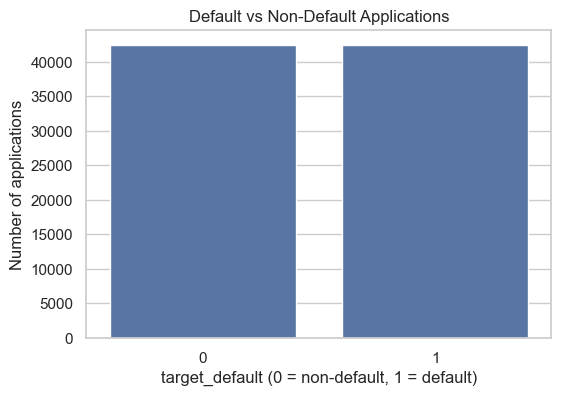

In [9]:
# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=apps_clean, x='target_default')
plt.title('Default vs Non-Default Applications')
plt.xlabel('target_default (0 = non-default, 1 = default)')
plt.ylabel('Number of applications')
plt.show()

In [10]:
# Summary statistics by default status
summary_by_target = apps_clean.groupby('target_default')[[
    'requested_amount_usd',
    'interest_rate',
    'annual_income_usd',
    'debt_to_income_ratio',
    'credit_score_low',
    'revolving_utilization'
]].median().round(2)

display(summary_by_target)

,requested_amount_usd,interest_rate,annual_income_usd,debt_to_income_ratio,credit_score_low,revolving_utilization
target_default,,,,,,
0,12000.0,11.53,65000.0,17.54,690.0,50.6
1,14400.0,14.65,60000.0,20.50,680.0,54.7


,default_rate,count
risk_grade_band,,
G,0.799366,947
F,0.791317,2741
E,0.736253,8311
D,0.649679,14775
C,0.535104,25111
B,0.380462,21169
A,0.197974,11946


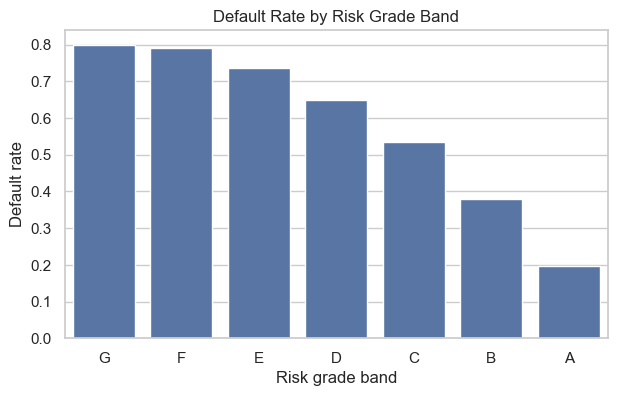

In [11]:
# Default rate by risk grade
risk_default = (
    apps_clean.groupby('risk_grade_band')['target_default']
    .agg(default_rate='mean', count='count')
    .sort_values('default_rate', ascending=False)
)
display(risk_default)

plt.figure(figsize=(7, 4))
sns.barplot(data=risk_default.reset_index(), x='risk_grade_band', y='default_rate')
plt.title('Default Rate by Risk Grade Band')
plt.xlabel('Risk grade band')
plt.ylabel('Default rate')
plt.show()

,default_rate,count
loan_purpose,,
small_business,0.624402,836
moving,0.622793,623
moving,0.615385,13
major_purchase,0.586957,46
small_business,0.533333,15
medical,0.521459,932
debt_consolidation,0.520023,49344
other,0.510461,4684
debt_consolidation,0.504202,1547


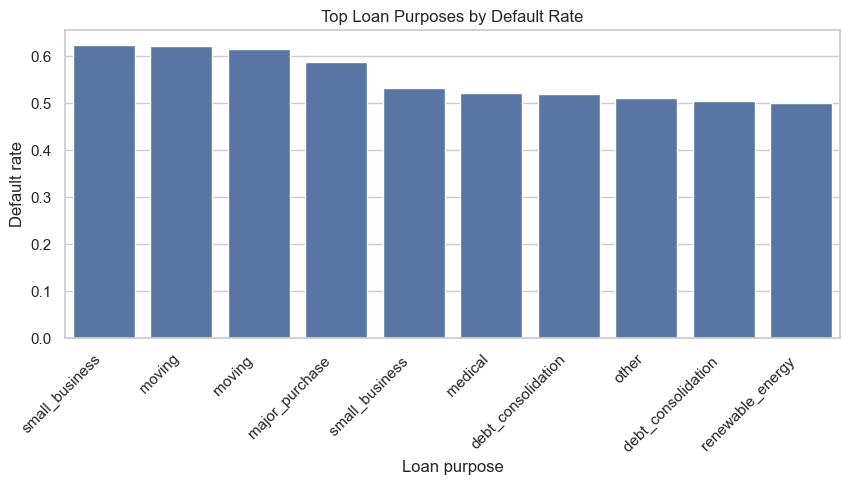

In [12]:
# Default rate by loan purpose
purpose_default = (
    apps_clean.groupby('loan_purpose')['target_default']
    .agg(default_rate='mean', count='count')
    .sort_values('default_rate', ascending=False)
)
display(purpose_default.head(10))

plt.figure(figsize=(10, 4))
sns.barplot(data=purpose_default.head(10).reset_index(), x='loan_purpose', y='default_rate')
plt.title('Top Loan Purposes by Default Rate')
plt.xlabel('Loan purpose')
plt.ylabel('Default rate')
plt.xticks(rotation=45, ha='right')
plt.show()

In [13]:
# Default rate by housing status and income verification
housing_default = (
    apps_clean.groupby('housing_status')['target_default']
    .agg(default_rate='mean', count='count')
    .sort_values('default_rate', ascending=False)
)
verification_default = (
    apps_clean.groupby('income_verification_status')['target_default']
    .agg(default_rate='mean', count='count')
    .sort_values('default_rate', ascending=False)
)

display(housing_default)
display(verification_default)

,default_rate,count
housing_status,,
ANY,1.000000,1
rent,0.551763,879
RENT,0.549493,35338
OWN,0.507798,9425
own,0.481172,239
mortgage,0.474677,1007
MORTGAGE,0.451759,38111


,default_rate,count
income_verification_status,,
Verified,0.567004,26603
Source Verified,0.506092,36936
Not Verified,0.406458,21461


In [14]:
# Default rate by region, showing regions with at least 100 applications
region_default = (
    apps_clean.groupby('region_code')['target_default']
    .agg(default_rate='mean', count='count')
    .query('count >= 100')
    .sort_values('default_rate', ascending=False)
)
display(region_default.head(10))

,default_rate,count
region_code,,
NE,0.630573,314
AR,0.581102,635
LA,0.573501,1034
FL,0.568807,109
AL,0.561828,1116
AK,0.559322,177
ND,0.555556,117
OK,0.545998,837
MS,0.543599,539


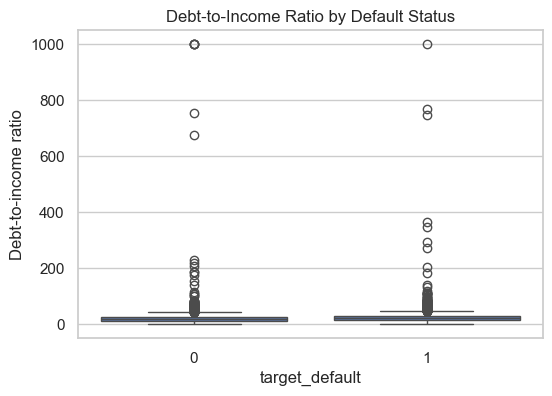

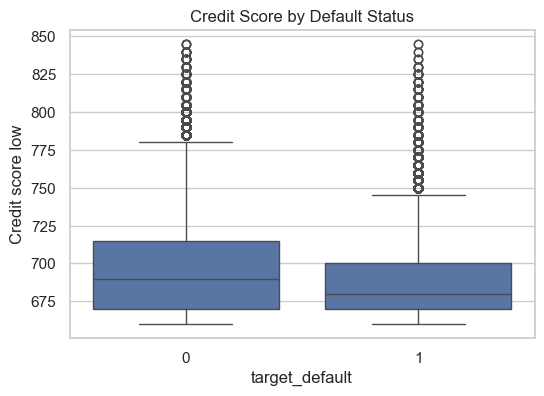

In [15]:
# Boxplots for key numeric risk indicators
plt.figure(figsize=(6, 4))
sns.boxplot(data=apps_clean, x='target_default', y='debt_to_income_ratio')
plt.title('Debt-to-Income Ratio by Default Status')
plt.xlabel('target_default')
plt.ylabel('Debt-to-income ratio')
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(data=apps_clean, x='target_default', y='credit_score_low')
plt.title('Credit Score by Default Status')
plt.xlabel('target_default')
plt.ylabel('Credit score low')
plt.show()

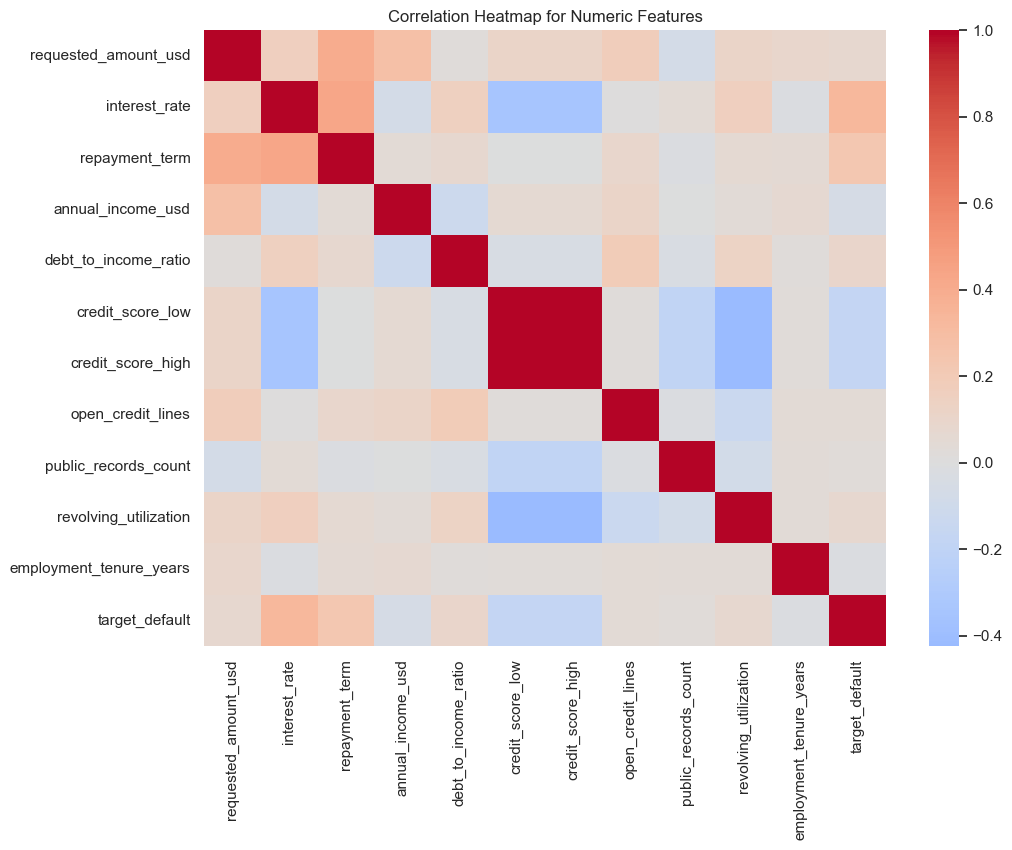

In [16]:
# Correlation heatmap for numeric variables
corr_cols = [
    'requested_amount_usd', 'interest_rate', 'repayment_term', 'annual_income_usd',
    'debt_to_income_ratio', 'credit_score_low', 'credit_score_high',
    'open_credit_lines', 'public_records_count', 'revolving_utilization',
    'employment_tenure_years', 'target_default'
]

plt.figure(figsize=(11, 8))
sns.heatmap(apps_clean[corr_cols].corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap for Numeric Features')
plt.show()

## 6. Supplementary EDA for the inquiries dataset

The inquiry dataset does not include the final default outcome and cannot be directly joined to the application dataset because no application ID is provided. However, it still supports the project by showing additional credit inquiry patterns.

In [18]:
print('Inquiry date range:', inq_clean['application_date'].min(), 'to', inq_clean['application_date'].max())
print('Inquiry missing values:')
display(inq_clean.isna().sum().sort_values(ascending=False))

display(inq_clean[['requested_amount_usd', 'screening_score', 'debt_to_income', 'employment_tenure_years']].describe())

# Screening score by region
screening_by_region = (
    inq_clean.groupby('region_code')['screening_score']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
display(screening_by_region)

Inquiry date range: 2007-05-26 00:00:00 to 2009-04-23 00:00:00
Inquiry missing values:


screening_score            4513
region_code                  21
request_title                 9
employment_tenure_text        2
employment_tenure_years       2
requested_amount_usd          0
application_date              0
debt_to_income_text           0
policy_code                   0
debt_to_income                0
dtype: int64

,requested_amount_usd,screening_score,debt_to_income,employment_tenure_years
count,44985.000000,40472.000000,4.498500e+04,44983.000000
mean,9039.100737,574.057966,2.793474e+03,3.520975
std,6901.470645,154.742359,3.079517e+04,3.543959
min,500.000000,0.000000,-1.000000e+00,0.000000
25%,3500.000000,513.000000,2.160000e+00,0.000000
50%,7000.000000,609.000000,1.384000e+01,2.000000
75%,14000.000000,670.000000,2.842000e+01,6.000000
max,40000.000000,828.000000,3.626400e+06,10.000000


region_code
WY     703.500000
MT     659.000000
KS     654.200000
NM     632.500000
NJ     628.500000
MA     624.592593
HI     621.666667
NY     615.350000
MN     615.076923
IN     611.363636
Name: screening_score, dtype: float64

## 7. Feature engineering and feature selection

The model uses numeric loan, borrower, and credit indicators plus selected categorical variables. Post-outcome fields are excluded to avoid target leakage.

**Excluded fields:**
- `outcome_status`: used to create the target.
- `target_default`: target variable, not a predictor.
- `last_payment_amount_usd`: repayment outcome information that would not be known at application time.
- Original text columns replaced by cleaned numeric versions.

In [19]:
numeric_features = [
    'requested_amount_usd',
    'monthly_installment_usd',
    'interest_rate',
    'repayment_term',
    'annual_income_usd',
    'debt_to_income_ratio',
    'credit_score_low',
    'credit_score_high',
    'open_credit_lines',
    'public_records_count',
    'revolving_utilization',
    'employment_tenure_years'
]

categorical_features = [
    'risk_grade_band',
    'housing_status',
    'income_verification_status',
    'loan_purpose',
    'region_code'
]

X = apps_clean[numeric_features + categorical_features]
y = apps_clean['target_default']

print('Modeling rows:', X.shape[0])
print('Number of starting features before one-hot encoding:', X.shape[1])

Modeling rows: 85000
Number of starting features before one-hot encoding: 17


## 8. Train/test split and preprocessing pipeline

The train/test split is stratified so that the proportion of default and non-default loans remains balanced in both sets. The preprocessing pipeline imputes missing values, scales numeric features, and one-hot encodes categorical features.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

try:
    onehot = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=True)
except TypeError:
    onehot = OneHotEncoder(handle_unknown='ignore', drop='first', sparse=True)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', onehot)
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Training target balance:')
display(y_train.value_counts(normalize=True).round(3))
print('Testing target balance:')
display(y_test.value_counts(normalize=True).round(3))

Training target balance:


target_default
1    0.5
0    0.5
Name: proportion, dtype: float64

Testing target balance:


target_default
0    0.5
1    0.5
Name: proportion, dtype: float64

## 9. Build classification models

Two models are trained as required by the assignment:

1. **Logistic Regression** - useful as an interpretable baseline model for binary classification.
2. **Random Forest Classifier** - useful for capturing non-linear relationships and interactions among variables.

In [22]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=80,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1,
        max_depth=15,
        min_samples_leaf=5
    )
}

trained_models = {}
results = []

for model_name, model in models.items():
    clf = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    trained_models[model_name] = clf
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).round(4)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6623,0.6588,0.6734,0.6660,0.7230
1,Random Forest,0.6621,0.6588,0.6725,0.6655,0.7237


## 10. Model evaluation

Accuracy alone is not enough for credit risk analysis. Precision, recall, F1-score, and ROC-AUC are also used because the cost of missing a likely default can be high.

In [24]:
for model_name, clf in trained_models.items():
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    print('\n' + '=' * 80)
    print(model_name)
    print('=' * 80)
    print(classification_report(y_test, y_pred))
    print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 4))


Logistic Regression
              precision    recall  f1-score   support

           0       0.67      0.65      0.66      8500
           1       0.66      0.67      0.67      8500

    accuracy                           0.66     17000
   macro avg       0.66      0.66      0.66     17000
weighted avg       0.66      0.66      0.66     17000

ROC-AUC: 0.723

Random Forest
              precision    recall  f1-score   support

           0       0.67      0.65      0.66      8500
           1       0.66      0.67      0.67      8500

    accuracy                           0.66     17000
   macro avg       0.66      0.66      0.66     17000
weighted avg       0.66      0.66      0.66     17000

ROC-AUC: 0.7237


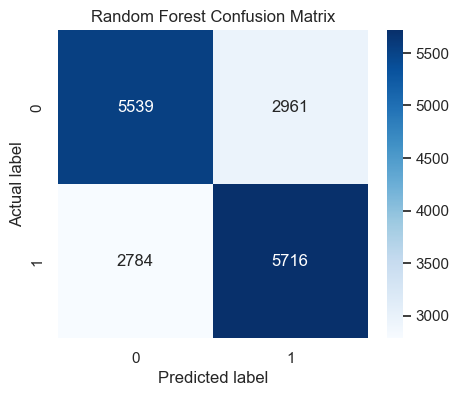

Best model by ROC-AUC: Random Forest


In [25]:
# Confusion matrix for the slightly stronger model by ROC-AUC
best_model_name = results_df.sort_values('ROC-AUC', ascending=False).iloc[0]['Model']
best_model = trained_models[best_model_name]
y_best_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'{best_model_name} Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.show()

print('Best model by ROC-AUC:', best_model_name)

,feature,importance
2,num__interest_rate,0.206210
3,num__repayment_term,0.110424
5,num__debt_to_income_ratio,0.065338
6,num__credit_score_low,0.053989
1,num__monthly_installment_usd,0.051277
15,cat__risk_grade_band_E,0.050181
4,num__annual_income_usd,0.045709
7,num__credit_score_high,0.043641
0,num__requested_amount_usd,0.042602
10,num__revolving_utilization,0.039564


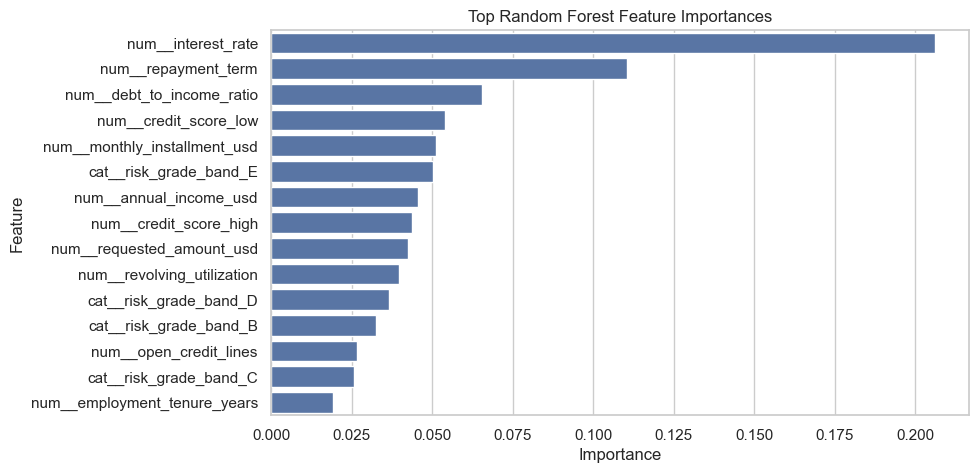

In [26]:
# Feature importance for Random Forest
rf_model = trained_models['Random Forest']
try:
    feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()
    importances = rf_model.named_steps['model'].feature_importances_
    feature_importance = (
        pd.DataFrame({'feature': feature_names, 'importance': importances})
        .sort_values('importance', ascending=False)
        .head(15)
    )
    display(feature_importance)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=feature_importance, x='importance', y='feature')
    plt.title('Top Random Forest Feature Importances')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.show()
except Exception as e:
    print('Feature importance could not be displayed:', e)

## 11. Business insights and recommendation

The analysis suggests that credit default risk is associated with a combination of pricing, borrower affordability, credit quality, and loan category. Higher interest rates, higher debt-to-income ratios, lower credit scores, and certain risk grades or loan purposes tend to show higher default risk.

The Random Forest model performs slightly better by ROC-AUC in this run, while Logistic Regression remains useful as an easier-to-explain benchmark. For business use, the recommended approach is to use the stronger model as a screening support tool, not as the only decision-making basis.

## 12. Limitations and future work

- The model is based on historical outcomes, so it may reflect patterns in past underwriting decisions.
- Some variables may be correlated with lender decisions rather than borrower behavior.
- The inquiry dataset could not be joined to the application dataset due to the absence of a common identifier.
- Future work should include threshold tuning, cross-validation, fairness checks, and additional model types such as gradient boosting.